# Support Vector Regression (SVR)

Notebook ini menggunakan `Salary_Data.csv` untuk memprediksi gaji berdasarkan lama pengalaman kerja. SVR adalah model regresi; fitur dan target diskalakan karena SVR sensitif terhadap skala data.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
# Pastikan Salary_Data.csv berada di folder yang sama dengan notebook ini.
data = pd.read_csv("Salary_Data.csv")
data.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [5]:
# YearsExperience menjadi fitur (X), sedangkan Salary menjadi target (y).
X = data[["YearsExperience"]]
y = data["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Fit scaler hanya pada data latih agar tidak terjadi data leakage.
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.to_numpy().reshape(-1, 1)).ravel()

model_svr = SVR(kernel="rbf", C=100, epsilon=0.1, gamma="scale")
model_svr.fit(X_train_scaled, y_train_scaled)

SVR(C=100)

In [6]:
# Prediksi dikembalikan ke satuan gaji asli sebelum evaluasi.
y_pred_scaled = model_svr.predict(X_test_scaled).reshape(-1, 1)
y_pred = scaler_y.inverse_transform(y_pred_scaled).ravel()

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE : {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²  : {r2:.4f}")

hasil = pd.DataFrame({
    "Pengalaman (tahun)": X_test["YearsExperience"].to_numpy(),
    "Gaji aktual": y_test.to_numpy(),
    "Prediksi SVR": y_pred,
})
hasil

MAE : 5,994.69
RMSE: 7,343.23
R²  : 0.8944


,Pengalaman (tahun),Gaji aktual,Prediksi SVR
0,9.6,112635.0,115075.695154
1,4.9,67938.0,66081.055106
2,8.2,113812.0,102813.731465
3,5.3,83088.0,71932.360390
4,3.2,64445.0,56263.241797
5,3.7,57189.0,58523.828165


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


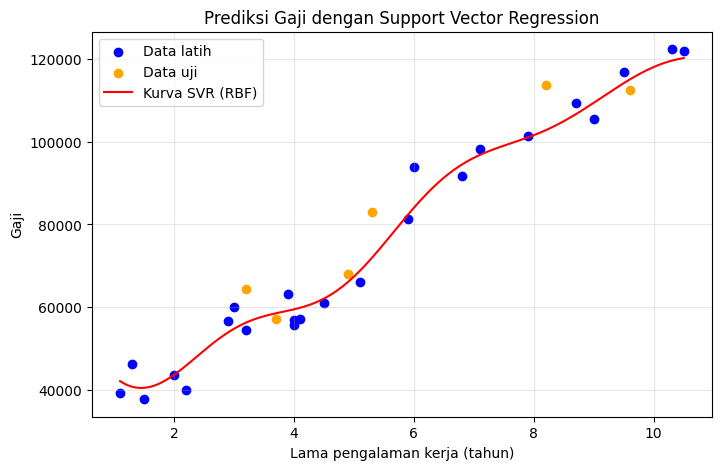

In [7]:
# Gambar kurva SVR dan data aktual.
X_plot = np.linspace(X["YearsExperience"].min(), X["YearsExperience"].max(), 200).reshape(-1, 1)
X_plot_scaled = scaler_X.transform(X_plot)
y_plot_scaled = model_svr.predict(X_plot_scaled).reshape(-1, 1)
y_plot = scaler_y.inverse_transform(y_plot_scaled).ravel()

plt.figure(figsize=(8, 5))
plt.scatter(X_train["YearsExperience"], y_train, color="blue", label="Data latih")
plt.scatter(X_test["YearsExperience"], y_test, color="orange", label="Data uji")
plt.plot(X_plot.ravel(), y_plot, color="red", label="Kurva SVR (RBF)")
plt.xlabel("Lama pengalaman kerja (tahun)")
plt.ylabel("Gaji")
plt.title("Prediksi Gaji dengan Support Vector Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [8]:
# Contoh memprediksi gaji untuk pengalaman kerja 5 tahun.
pengalaman_baru = np.array([[5.0]])
pengalaman_baru_scaled = scaler_X.transform(pengalaman_baru)
prediksi_baru_scaled = model_svr.predict(pengalaman_baru_scaled).reshape(-1, 1)
prediksi_gaji = scaler_y.inverse_transform(prediksi_baru_scaled)[0, 0]

print(f"Perkiraan gaji untuk pengalaman 5 tahun: {prediksi_gaji:,.2f}")

Perkiraan gaji untuk pengalaman 5 tahun: 67,389.37


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
